# Practice 3. Reading industrial documents: six readers, one regulation

**ML in Industry 2026 · Topic 3: Industrial documents**

## Goal

An engineer asks: *"After the bearing change, pump P-101 vibrates at 4.8 mm/s. Is this normal?"*
The answer is in Table 3 of regulation R-12, clause 4.3, and the plant archive has R-12 only as a **scan**.
Before any model can answer, something has to *read* that page. Today we measure how well different
readers do it, and we build the chunk store that practice 4 (RAG) will search.

```
scan of R-12 ──► reader ──► text, tables, clauses ──► chunks with metadata ──► store/  (input of practice 4)
                  │
   PyMuPDF · EasyOCR (or Tesseract) · Docling · dots.ocr (document VLM, replay)
   · a general VLM: Qwen 3.8 27B, Qwen3.5 4B, a frontier model (replay)
```

## Steps and what you should see

| Step | What we do | Expected result |
|------|------------|-----------------|
| 1 | Setup and smoke test | the model answers text **and** reads an image |
| 2 | The archive and triage | 2 digital PDFs, 3 scans, 2 images |
| 3 | One page, six readers | the same Table 3 page read six ways; the text layer of a scan is empty; a document VLM returns boxes |
| 4 | The whole scanned set | CER, numbers, length, repetitions, seconds per page |
| 5 | Tables | rows recovered per reader; one table in Markdown, HTML and JSON |
| 6 | A VLM on a drawing and a nameplate | tags with precision and recall; nameplate fields |
| 7 | Structure, chunks, metadata, revisions | a chunk store with two revisions of R-12 |
| 8 | Mini-eval end-to-end | 50 questions, accuracy with interval, paired comparison, where answers were lost |

## Success criteria

- `store/chunks.jsonl` has all documents; every chunk has `doc_id`, `revision` (for R-12), `clause`, `page`.
- Your reading table (step 4) and your mini-eval table (step 8) are close to `reference/results.md`;
  the paired comparison gives the same verdicts.

## Live or replay

Every model call goes through one OpenAI-compatible client. If your model answers, the notebook calls it
**live**. If not, it **replays** the lecturer's saved answers for exactly the same requests.
Heavy readers (EasyOCR, Docling) do not run in the notebook: their outputs are in `data/parsed/`, and
`scripts/run_readers.py` reproduces them on your machine. dots.ocr and the frontier model run on the
lecturer's key: you always see their saved answers.

## Common problems

| Problem | What to do |
|---------|-----------|
| `Mode: REPLAY` but you have the course token | check `COURSE_LLM_BASE_URL` and `COURSE_LLM_API_KEY` in `.env`; run `uv run python -m plant_assistant.smoke_test course` |
| the smoke test passes text but fails the image | the model is not a VLM; for Ollama check `ollama show <model>` (needs "vision") |
| `ReplayMiss` | you changed a prompt, a page render or a saved reader output: replay works only for unchanged requests |
| Tesseract: `TesseractNotFoundError` or no `rus` | install Tesseract and the Russian language data (README, "Readers on your machine") |
| Docling or EasyOCR download weights on the first run | expected; run `scripts/run_readers.py` once before the session, or use the saved outputs |
| Docling takes minutes per document on CPU | expected (about 30 s per page on the lecturer's CPU); use `data/parsed/docling.jsonl` |
| a VLM answer is empty, `finish_reason = length` | thinking mode is on and used all tokens: keep it off for transcription |

## 0. Where we are going

The final tables of this practice, measured by the lecturer. At the end you will know where every number
comes from.

In [1]:
import pandas as pd
from IPython.display import HTML, Markdown, display

from plant_assistant import REFERENCE_DIR

pd.set_option("display.max_colwidth", 200)
pd.set_option("display.float_format", "{:.3f}".format)
display(Markdown("**Reading the scans** (CER: lower is better; numbers: share kept)"))
display(pd.read_csv(REFERENCE_DIR / "reading.csv", index_col=0))
display(Markdown("**Mini-eval: 50 questions about the scans** (same model answers, only the reader changes)"))
display(pd.read_csv(REFERENCE_DIR / "qa.csv", index_col=0))

**Reading the scans** (CER: lower is better; numbers: share kept)

,CER P-205 (zh),CER PS-101,CER R-12,numbers_exact,numbers_value,length_ratio,repeated,sec_per_page,usd_per_page
"PyMuPDF, text layer",1.000,1.000,1.000,0.000,0.000,0.000,0.000,0.000,0.000
EasyOCR,0.478,0.211,0.203,0.938,0.952,1.005,0.000,20.966,0.000
Docling (+EasyOCR),0.679,0.316,0.372,0.751,0.787,0.735,0.000,19.354,0.000
"dots.ocr 1.5, document VLM (replay)",0.000,0.003,0.020,1.000,1.000,1.000,0.000,16.662,0.000
"Qwen3.5 4B, local VLM",0.000,0.004,0.062,0.992,0.992,1.006,0.000,12.592,0.000
"Qwen 3.8 27B, course VLM",0.000,0.001,0.032,1.000,1.000,1.010,0.000,9.852,0.000
gpt-6.1-sol (replay),0.004,0.022,0.032,1.000,1.000,1.014,0.000,10.691,0.014


**Mini-eval: 50 questions about the scans** (same model answers, only the reader changes)

,accuracy,95% CI,table,text,datasheet,rare_language,not_stated,lost in reading,lost in the model
reader,,,,,,,,,
Born-digital original (ceiling),0.980,90%–100%,14/14,17/17,6/6,5/5,7/8,0,1
"PyMuPDF, text layer",0.160,8%–29%,0/14,0/17,0/6,0/5,8/8,42,0
EasyOCR,0.840,71%–92%,11/14,14/17,5/6,4/5,8/8,8,0
Docling (+EasyOCR),0.560,42%–69%,4/14,11/17,4/6,1/5,8/8,22,0
"dots.ocr 1.5, document VLM (replay)",0.980,90%–100%,14/14,17/17,6/6,5/5,7/8,0,1
"Qwen3.5 4B, local VLM",0.980,90%–100%,14/14,17/17,6/6,5/5,7/8,0,1
"Qwen 3.8 27B, course VLM",0.980,90%–100%,14/14,17/17,6/6,5/5,7/8,0,1
gpt-6.1-sol (replay),0.980,90%–100%,14/14,17/17,6/6,5/5,7/8,0,1


## 1. Setup and smoke test

Profiles are in `models.toml`, secrets in `.env` (as in practice 1). All profiles of this practice are VLMs:
the course Qwen 3.8 27B, the local Qwen3.5 4B in Ollama, and the lecturer's frontier model (replay only).

In [2]:
import json
import os

from plant_assistant import DOCS_DIR, REPLAY_DIR, RUNS_DIR
from plant_assistant.config import get_profile, list_profiles, load_env
from plant_assistant.images import vision_message
from plant_assistant.llm import CallLogger, LLMClient, ReplayClient
from plant_assistant.smoke_test import test_image

load_env()
PROFILE = os.environ.get("PRACTICE_PROFILE", "course")  # course or local
print("PROFILE =", PROFILE)
pd.DataFrame([{"profile": k, "description": v} for k, v in list_profiles().items()])

PROFILE = course


,profile,description
0,local,"Small open-weight VLM on your laptop via Ollama (Qwen3.5 4B, Q4, vision)"
1,course,"Course model Qwen 3.8 27B (multimodal) via LiteLLM + vLLM, thinking off"
2,gpt-6.1-sol,"OpenAI gpt-6.1-sol, frontier API (lecturer key)"
3,dots-ocr,"dots.ocr 1.5, document VLM: layout boxes + text (lecturer key, self-hosted)"


In [3]:
def model_reads_images(profile_name: str) -> bool:
    # One text call and one image call. No network retries: if the model is not there, we want to know now.
    try:
        client = LLMClient(get_profile(profile_name), max_network_retries=0)
    except ValueError as exc:  # profile not configured (no URL or key)
        print(f"{profile_name}: {exc}")
        return False
    seen = client.chat([vision_message("What is written in the image? Answer with the text only.", test_image())])
    print(f"{profile_name}: {seen.content.strip()[:30]!r} ({seen.latency_s:.1f}s)" if seen.ok else seen.error)
    return seen.ok and "417" in seen.content


LIVE = model_reads_images(PROFILE)
print("Mode:", f"LIVE calls to {PROFILE}" if LIVE else "REPLAY of the lecturer's saved answers (course model)")


def client_for(task: str):
    # Live model if it answers, otherwise the lecturer's saved answers of the course model for this task.
    if LIVE:
        return LLMClient(get_profile(PROFILE), logger=CallLogger(RUNS_DIR / f"my-{PROFILE}" / f"{task}.jsonl"))
    return ReplayClient(REPLAY_DIR / f"{task}_course.jsonl")

course: 'PUMP P417' (1.3s)
Mode: LIVE calls to course


## 2. The archive and triage

What the plant has: two born-digital revisions of R-12, a scan of revision 3 (the paper copy in the
control room), two scanned pump datasheets (one from a Chinese supplier), a P&ID fragment and a photo of a
nameplate. All documents are **synthetic**: R-12, the plant and the numbers are invented for the course.

Triage decides the route of every file: a born-digital PDF goes to the text layer, a scan needs recognition.

> **Predict, then run.** How many of the 7 files will be detected as scans?

In [4]:
from plant_assistant.docs import load_registry, triage_archive

registry = pd.DataFrame(load_registry())
tri = pd.DataFrame([t.__dict__ for t in triage_archive()])
registry.merge(tri[["file", "chars_per_page", "images", "kind"]], on="file")

,file,doc_id,kind_x,revision,status,pages,chars_per_page,images,kind_y
0,R-12_rev2.pdf,R-12,regulation,2,superseded,6,1310.700,0,digital
1,R-12_rev3.pdf,R-12,regulation,3,in force,6,1310.500,0,digital
2,R-12_rev3_scan.pdf,R-12,regulation,3,in force,6,0.000,6,scan
3,PS-101_scan.pdf,PS-101,datasheet,,,1,0.000,1,scan
4,DS-P-205_scan.pdf,DS-P-205,datasheet,,,1,0.000,1,scan
5,PID-R12-001.png,PID-R12-001,drawing,3,,1,0.000,1,image
6,nameplate_P-101.jpg,NP-P-101,photo,,,1,0.000,1,image


Two signals are enough here: characters in the text layer and pictures on the page. A real archive also has
**mixed** files (a scan with a poor OCR layer, a digital PDF with scanned attachments): there triage is per page.

## 3. One page, six readers

Page 4 of the scanned R-12: Table 3 with the vibration limits, merged cells, the page is slightly rotated.

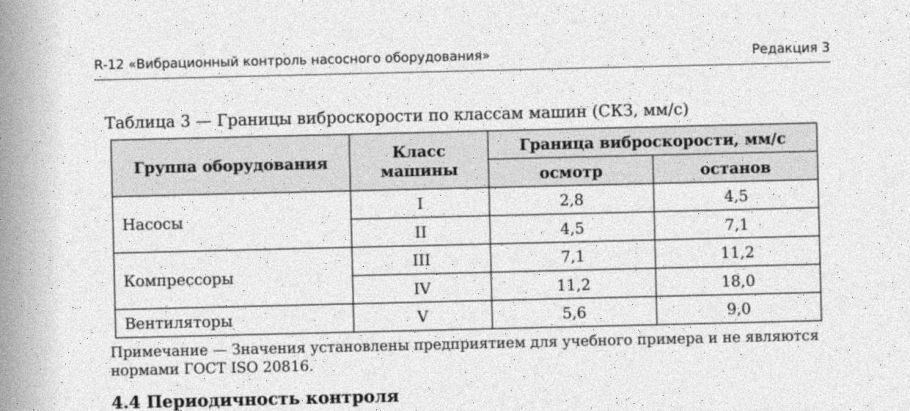

In [5]:
from IPython.display import Image as IPImage

from plant_assistant.images import jpeg_bytes, render_page


def show_jpeg(img) -> None:
    display(IPImage(jpeg_bytes(img, quality=80)))  # a scan as JPEG keeps the notebook small


SCAN = DOCS_DIR / "R-12_rev3_scan.pdf"
PAGE = 4
page_img = render_page(SCAN, PAGE, dpi=110)
show_jpeg(page_img.crop((0, 0, page_img.width, int(page_img.height * 0.32))))

**Reader 1: PyMuPDF**, the text layer. It runs in milliseconds and is perfect on born-digital PDFs.

In [6]:
from plant_assistant.readers import read_pymupdf

text_layer = read_pymupdf(SCAN)[PAGE - 1]
print(f"characters on page {PAGE}: {len(text_layer['text'].strip())}  ({text_layer['seconds'] * 1000:.1f} ms)")

characters on page 4: 0  (0.0 ms)


Zero characters: a scan has no text layer. If triage had sent this file to PyMuPDF, the system would index an
empty page **without any error**. This is the first silent loss of the pipeline.

> **Poll.** Which reader will have the lowest CER on the scanned pages? (a) EasyOCR (b) Docling (c) a VLM (d) about the same

**Readers 2 and 3: a classic OCR engine and a document parser.** Their outputs are saved in `data/parsed/`
(EasyOCR and Docling need PyTorch and model weights; `scripts/run_readers.py` reproduces them).

In [7]:
from plant_assistant.evaluate import READER_NAMES
from plant_assistant.readers import available_readers, load_outputs

READERS = [r for r in ["pymupdf", "tesseract", "easyocr", "docling", "vlm:dots-ocr", "vlm:local", "vlm:course",
                       "vlm:gpt-6.1-sol"]
           if r in available_readers()]
print("saved readers:", READERS)


def show_side_by_side(texts: dict, n_lines: int = 30) -> None:
    cols = "".join(
        f"<td style='vertical-align:top'><b>{name}</b><pre style='font-size:11px;white-space:pre-wrap'>"
        + "\n".join(t.splitlines()[:n_lines]).replace("<", "&lt;") + "</pre></td>" for name, t in texts.items())
    display(HTML(f"<table><tr>{cols}</tr></table>"))


ocr_readers = [r for r in ("tesseract", "easyocr", "docling") if r in READERS]
show_side_by_side({READER_NAMES[r]: load_outputs(r)[("R-12_rev3_scan.pdf", PAGE)]["text"] for r in ocr_readers})

saved readers: ['pymupdf', 'easyocr', 'docling', 'vlm:dots-ocr', 'vlm:local', 'vlm:course', 'vlm:gpt-6.1-sol']


"EasyOCRРедакция 3 R-12 ~Вибрационный контроль насосного оборудования"" Таблица 3 Границы виброскорости по классам машин (СКЗ; мм/с) Класс Граница виброскорости; мм/с Группа оборудования машины осмотр останов 2;8 4,5 Насосы 4,5 7,1 7,1 11,2 Компрессоры IV 11,2 18,0 V 5,6 9,0 Вентиляторы Прнмечание Значения установлены предприятием для учебного примера и не являются нормами ГОСТ ISO 20816. 4.4 Периодичность контроля 4.4.1 Периодический контроль переносным виброметром выполняют каждые 720 часов наработки но не реже одного раза в месяц: 4.4.2 После ремонта; замены подшипников или центровки измерения выполняют в течение 8 часов после пуска. 4.4.3 Оборудование классов III и IV оснащают стационарной системой контроля C непрерывной регистрацией виброскорости. 4.5 Классы машин 4.5.1 Класс машины определяют по таблице' 2 по типу оборудования и мощности приводного двигателя. 4.5,2 Насосы c приводом мощностью до 15 кВт включительно относятся к классу 1 свышё 15 кВт к классу II Таблица 2 Классы машин Тип оборудования Мощность привода Класс: до 15 кВт 1 Центробежный насос свыше 15 кВт II до 300 кВт IIl","Docling (+EasyOCR)Таблица 3 Границы ниброскорости по классам машин (СКЗ, мм/c) Вантиляторы Значения установлены предприятнем для учебного примера и не являются Прнмачанне нормами ГОСТ I5O 20816. | Группа оборудования | Класс машины | осмотр | останов | |-----------------------|----------------|----------|-----------| | Насосы | | 2 8 | 4,5 | | Насосы | | 4,5 | 7,1 | | Кампрессоры | | | 11 2 | | Кампрессоры | IV | 11,2 | 18,0 | | | V | | 9,0 | ## 4.4 Пернодичность контроля - 4,4,2 После ремонта, замены подшипников или центровки измерения выполняют ₽ теченне 8 часов после пуска - 4.4.1 Пернодический контроль переносным виброметром выполняют каждые 720 часов наработки , но не реже одного раза в месяц - 4.4.3 Оборудование классов III и IV оснащают стацнонарной системой контроля непрерывнон регистрацией виброскорости . ## 4.5 Классы машин - 4.5.2 Насосы c приводом мощностью до 15 кВт включительно относятся к классу 1; свыше 15 кВт к классу II 2. 4.5,1 Класс машины определяют по таблице 2 по типу оборудовання и мощностн приводного днигателя. ## Таблнца 2 Классн машин | | Мошность принода | Класс | |--------------------|----------------------------|---------| | Центробежный насос | Тип оборудовання до 15 кВт | 1 | | Центробежный насос | сныше 15 кВт | | | Компрессор | до 300 кВт | |"


Look at Table 3. Where are the classes I, II, III? What happened to `2,8`? In which order are clauses 4.4.1 and
4.4.2? Every error here is **silent**: nothing crashes, the text just becomes a little wrong.

**Reader 4: a VLM.** The course Qwen 3.8 27B gets the page image and the prompt below. This call runs live.

In [8]:
from plant_assistant.readers import TRANSCRIBE_PROMPT, read_vlm

print(TRANSCRIBE_PROMPT)
vlm_page = read_vlm(SCAN, client_for("transcribe"), pages=[PAGE], reader_name=f"vlm:{PROFILE}")[0]
print(f"\n--- {vlm_page['reader']}: {vlm_page['seconds']:.1f}s, {vlm_page.get('completion_tokens')} output tokens ---\n")
print(vlm_page["text"][:1800])

Transcribe this scanned page exactly as written.
- Keep the original language, spelling, numbers, units and punctuation (for example, keep a decimal comma).
- Do not translate, correct, summarise or add anything.
- Keep the reading order: running header, headings, paragraphs, tables, notes, footer.
- Write headings and paragraphs as Markdown. Write every table as an HTML <table>, with rowspan and colspan for merged cells.
- If a part cannot be read, write [unreadable] instead of guessing.
Output only the transcription.



--- vlm:course: 7.4s, 942 output tokens ---

R-12 «Вибрационный контроль насосного оборудования»
Редакция 3

Таблица 3 — Границы виброскорости по классам машин (СКЗ, мм/с)

<table border="1">
 <tr>
  <th rowspan="2">Группа оборудования</th>
  <th rowspan="2">Класс<br>машины</th>
  <th colspan="2">Граница виброскорости, мм/с</th>
 </tr>
 <tr>
  <th>осмотр</th>
  <th>останов</th>
 </tr>
 <tr>
  <td rowspan="2">Насосы</td>
  <td>I</td>
  <td>2,8</td>
  <td>4,5</td>
 </tr>
 <tr>
  <td>II</td>
  <td>4,5</td>
  <td>7,1</td>
 </tr>
 <tr>
  <td rowspan="2">Компрессоры</td>
  <td>III</td>
  <td>7,1</td>
  <td>11,2</td>
 </tr>
 <tr>
  <td>IV</td>
  <td>11,2</td>
  <td>18,0</td>
 </tr>
 <tr>
  <td>Вентиляторы</td>
  <td>V</td>
  <td>5,6</td>
  <td>9,0</td>
 </tr>
</table>

Примечание — Значения установлены предприятием для учебного примера и не являются нормами ГОСТ ISO 20816.

### 4.4 Периодичность контроля

4.4.1 Периодический контроль переносным виброметром выполняют каждые 720 часов наработк

In [9]:
from plant_assistant.docs import load_gt_pages
from plant_assistant.metrics import page_scores

gt = load_gt_pages()
truth = gt[("R-12_rev3_scan.pdf", PAGE)]
one_page = {r: load_outputs(r)[("R-12_rev3_scan.pdf", PAGE)]["text"] for r in READERS}
one_page["vlm (your run)"] = vlm_page["text"]
pd.DataFrame({r: page_scores(truth, t) for r, t in one_page.items()}).T[
    ["cer", "numbers", "numbers_exact", "numbers_value", "length_ratio", "repeated"]]

,cer,numbers,numbers_exact,numbers_value,length_ratio,repeated
pymupdf,1.000,40.000,0.000,0.000,0.000,0.000
easyocr,0.141,40.000,0.975,0.975,0.984,0.000
docling,0.572,40.000,0.775,0.800,0.944,0.000
vlm:dots-ocr,0.017,40.000,1.000,1.000,1.000,0.000
vlm:local,0.017,40.000,1.000,1.000,0.999,0.000
vlm:course,0.017,40.000,1.000,1.000,1.000,0.000
vlm:gpt-6.1-sol,0.017,40.000,1.000,1.000,1.000,0.000
vlm (your run),0.017,40.000,1.000,1.000,1.000,0.000


- **CER** after removing the Markdown and HTML markup. It also counts a different order of table cells as errors.
- **numbers_exact / numbers_value**: share of the numbers of the page that the reader kept as written (`4,5`) and
  by value (`4.5` also counts). A gap between them means the reader *rewrote* numbers instead of reading them.
- **length_ratio, repeated**: the traces of the typical VLM failures: missing parts, invented parts, repetition loops.

**Reader 5: a document VLM.** dots.ocr (rednote hi lab) is a small model trained only to parse pages. With its own
layout prompt it returns every block of the page with a **category** and a **box**, and the text of the block
(tables as HTML). A general VLM gives text only. The box is what rule 1 of lecture 1, "show the source", needs:
a chunk can point to its place on the page. dots.ocr runs on the lecturer's server, so you see its saved answers.

19 blocks, 26s: ['Page-header', 'Page-header', 'Caption', 'Table', 'Text', 'Section-header', 'Text', 'Text'] ...


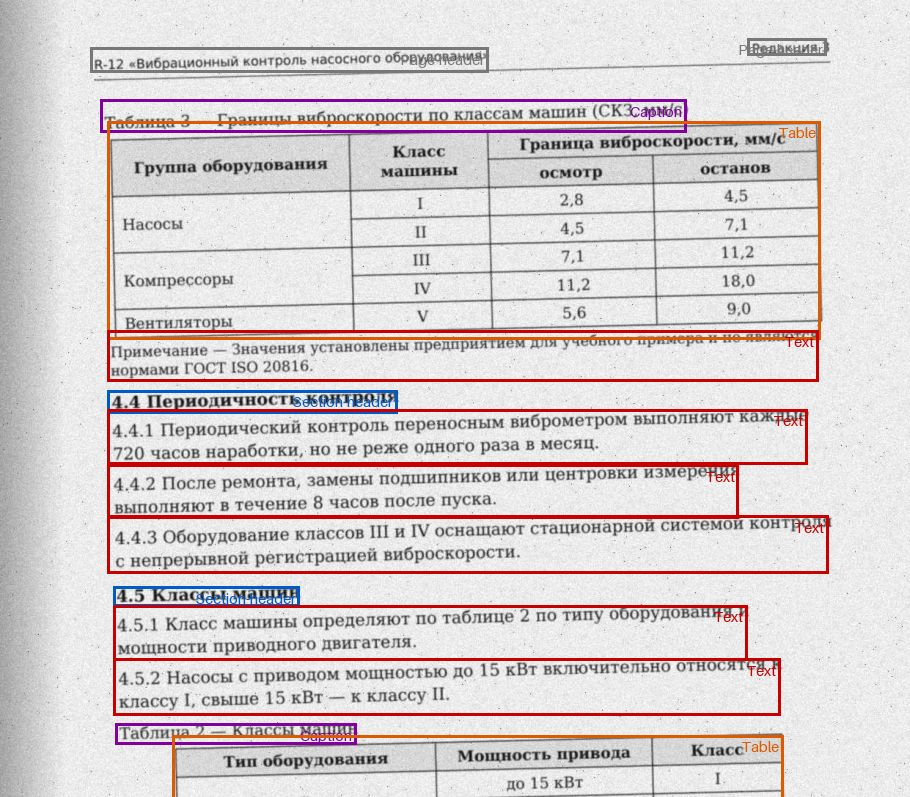

In [10]:
from plant_assistant.images import draw_layout
from plant_assistant.readers import DOTS_LAYOUT_PROMPT

dots = load_outputs("vlm:dots-ocr")[("R-12_rev3_scan.pdf", PAGE)]
print(f"{len(dots['layout'])} blocks, {dots['seconds']:.0f}s:", [b["category"] for b in dots["layout"]][:8], "...")
boxed = draw_layout(render_page(SCAN, PAGE, dpi=110), dots["layout"], dpi=110)
show_jpeg(boxed.crop((0, 0, boxed.width, int(boxed.height * 0.62))))

## 4. The whole scanned set

8 pages: R-12 revision 3 (6 pages), the datasheet of P-101 (Russian and English) and the datasheet of P-205
(Chinese). One of the R-12 pages is a "copy of a copy": faint, rotated, noisy.

In [11]:
from plant_assistant.evaluate import page_table, reading_summary

pages = page_table(READERS)
reading_summary(pages)

,CER P-205 (zh),CER PS-101,CER R-12,numbers_exact,numbers_value,length_ratio,repeated,sec_per_page,usd_per_page
"PyMuPDF, text layer",1.000,1.000,1.000,0.000,0.000,0.000,0.000,0.000,0.000
EasyOCR,0.478,0.211,0.203,0.938,0.952,1.005,0.000,20.966,0.000
Docling (+EasyOCR),0.679,0.316,0.372,0.751,0.787,0.735,0.000,19.354,0.000
"dots.ocr 1.5, document VLM (replay)",0.000,0.003,0.020,1.000,1.000,1.000,0.000,16.662,0.000
"Qwen3.5 4B, local VLM",0.000,0.004,0.062,0.992,0.992,1.006,0.000,12.592,0.000
"Qwen 3.8 27B, course VLM",0.000,0.001,0.032,1.000,1.000,1.010,0.000,9.852,0.000
gpt-6.1-sol (replay),0.004,0.022,0.032,1.000,1.000,1.014,0.000,10.691,0.014


In [12]:
# CER per page: where does each reader break?
cer_by_page = pages.pivot_table(index=["doc", "page"], columns="reader", values="cer").round(3)
cer_by_page.style.background_gradient(axis=None, cmap="Reds", vmin=0, vmax=0.6).format("{:.3f}")

> **Chat.** Look at the P-205 datasheet (Chinese). Did any VLM change a number or a unit? Type yes or no.

In [13]:
p205 = ("DS-P-205_scan.pdf", 1)
show_side_by_side({READER_NAMES[r]: load_outputs(r)[p205]["text"] for r in ("easyocr", "vlm:local", "vlm:course")
                   if r in READERS}, n_lines=40)
pages[pages["doc"] == "P-205 (zh)"][["reader", "cer", "numbers_exact", "numbers_value", "length_ratio"]]

EasyOCRЕLжtжё ж {us Р-205 #Лiёlj #ЖЖ LЪMRAa] (##ж$]) #5 ХВ8О-200 :Г вg XВ-2023-1182 #ГЕЛ 2023 #Же ж eay ei WXli ## mi/h 50 ;12 m 80. Ф} rlmin 2900 вWюz kW 37 Дл kg 520 йшЖ 6310 ztt {hzн] 1744 жи НТ250 [te ZG230-450 жtН 45# #х# {НITiч{а# Л Teaching document; not a real datasheet:,"Qwen3.5 4B, local VLM# 离心泵技术参数表 | 位号 | P-205 | |------|-------| | 制造商 | 华东泵业有限公司（教学示例） | | 型号 | XB80-200 | | 出厂编号 | XB-2023-1182 | | 出厂日期 | 2023 | ## 技术参数 | 参数 | 单位 | 数值 | |------|------|------| | 流量 | m³/h | 50 | | 扬程 | m | 80 | | 转速 | r/min | 2900 | | 电机功率 | kW | 37 | | 重量 | kg | 520 | | 轴承 | — | 6310 | | 密封 | — | 机械密封 | ## 材料 | 泵体 | HT250 | |------|-------| | 叶轮 | ZG230-450 | | 泵轴 | 45# | 教学文件，仅用于课程练习。Teaching document, not a real datasheet.","Qwen 3.8 27B, course VLM# 离心泵技术参数表 <table> <tr> <td>位号</td> <td>P-205</td> </tr> <tr> <td>制造商</td> <td>华东泵业有限公司（教学示例）</td> </tr> <tr> <td>型号</td> <td>XB80-200</td> </tr> <tr> <td>出厂编号</td> <td>XB-2023-1182</td> </tr> <tr> <td>出厂日期</td> <td>2023</td> </tr> </table> ## 技术参数 <table> <tr> <th>参数</th> <th>单位</th> <th>数值</th> </tr> <tr> <td>流量</td> <td>m³/h</td> <td>50</td> </tr> <tr> <td>扬程</td>"


,reader,cer,numbers_exact,numbers_value,length_ratio
0,pymupdf,1.000,0.000,0.000,0.000
8,easyocr,0.478,1.000,1.000,1.040
16,docling,0.679,1.000,1.000,0.406
24,vlm:dots-ocr,0.000,1.000,1.000,1.000
32,vlm:local,0.000,1.000,1.000,1.000
40,vlm:course,0.000,1.000,1.000,1.000
48,vlm:gpt-6.1-sol,0.004,1.000,1.000,1.004


The OCR engine was configured for Russian and English, like most Russian setups. On Chinese it does not fail
loudly: it returns confident garbage for the labels and correct digits. Note the tag: `P-205` may come back with
a **Cyrillic** `Р`. A VLM reads the labels, but check that it did not *translate* them or change the units.

## 5. Tables

In industrial documents the answer usually sits in a table. A table row is *recovered* when one row of the
output has the key cell (class `II`, tag `K-301`) and the right numbers in the right order.

In [14]:
from plant_assistant.evaluate import table_summary

table_summary(["digital"] + READERS)

,Table 3: recovered,Table 3: lost,Table A.1: recovered,Table A.1: lost
reader,,,,
Born-digital original (ceiling),0/5,"I, II, III, IV, V",0/6,"P-101, P-102, P-205, K-301, K-302, B-401"
"PyMuPDF, text layer",0/5,"I, II, III, IV, V",0/6,"P-101, P-102, P-205, K-301, K-302, B-401"
EasyOCR,2/5,"I, II, III",3/6,"P-205, K-302, B-401"
Docling (+EasyOCR),1/5,"I, II, III, V",1/6,"P-101, P-205, K-301, K-302, B-401"
"dots.ocr 1.5, document VLM (replay)",5/5,—,6/6,—
"Qwen3.5 4B, local VLM",5/5,—,6/6,—
"Qwen 3.8 27B, course VLM",5/5,—,6/6,—
gpt-6.1-sol (replay),5/5,—,6/6,—


The first row is the **text layer of the born-digital original**: every character is right (CER 0), and still
no table row is recovered, because every cell is on its own line. Text is not structure.

**One table in three representations.** We give the model Table 3 as Markdown (as many converters write it:
the merged cells are lost and the row of class II shifts to the left), as HTML (rowspan, colspan) and as JSON
records, and ask three questions about it.

> **Chat.** Which representation will give the correct answer for class II? Type md, html or json.

In [15]:
from plant_assistant.docs import load_json
from plant_assistant.tables import to_html, to_json_records, to_markdown_as_parsed

t3 = load_json("tables.json")["R-12_rev3/table3"]
REPS = {"markdown (merged cells lost)": to_markdown_as_parsed(t3["cells"], 2),
        "html (rowspan, colspan)": to_html(t3["cells"]),
        "json records": to_json_records(t3["cells"], 2)}
print(REPS["markdown (merged cells lost)"])

| Группа оборудования | Класс машины | Граница виброскорости, мм/с |  |
|---|---|---|---|
| осмотр | останов |  |  |
| Насосы | I | 2,8 | 4,5 |
| II | 4,5 | 7,1 |  |
| Компрессоры | III | 7,1 | 11,2 |
| IV | 11,2 | 18,0 |  |
| Вентиляторы | V | 5,6 | 9,0 |


In [16]:
from plant_assistant.qa import RESPONSE_FORMAT, grade, messages, parse_answer

REP_QUESTIONS = [("What is the inspection limit of vibration velocity for class II machines?", "4,5", "mm/s"),
                 ("What is the stop limit of vibration velocity for class II machines?", "7,1", "mm/s"),
                 ("What is the inspection limit of vibration velocity for class IV machines?", "11,2", "mm/s")]
rep_client = client_for("representations")
rows = []
for name, table in REPS.items():
    for question, value, unit in REP_QUESTIONS:
        r = rep_client.chat(messages(question, t3["caption"] + "\n\n" + table), response_format=RESPONSE_FORMAT,
                            meta={"task": "representation", "representation": name})
        ans = parse_answer(r.content)
        ok, reason = grade({"value": value, "unit": unit}, ans)
        rows.append({"representation": name, "question": question[:60], "expected": value,
                     "answer": (ans or {}).get("value"), "correct": ok, "prompt tokens": r.prompt_tokens})
pd.DataFrame(rows)

,representation,question,expected,answer,correct,prompt tokens
0,markdown (merged cells lost),What is the inspection limit of vibration velocity for class,"4,5","4,5",True,368
1,markdown (merged cells lost),What is the stop limit of vibration velocity for class II ma,"7,1","7,1",True,368
2,markdown (merged cells lost),What is the inspection limit of vibration velocity for class,"11,2","11,2",True,368
3,"html (rowspan, colspan)",What is the inspection limit of vibration velocity for class,"4,5","4,5",True,478
4,"html (rowspan, colspan)",What is the stop limit of vibration velocity for class II ma,"7,1","7,1",True,478
5,"html (rowspan, colspan)",What is the inspection limit of vibration velocity for class,"11,2","11,2",True,478
6,json records,What is the inspection limit of vibration velocity for class,"4,5","4,5",True,615
7,json records,What is the stop limit of vibration velocity for class II ma,"7,1","7,1",True,615
8,json records,What is the inspection limit of vibration velocity for class,"11,2","11,2",True,615


Two lessons. (1) The representation of a table is a design decision: HTML keeps merged cells and costs more
tokens, JSON records are best for parameter tables (one row = one item of equipment, a direct source for the
tools of topic 5). (2) A strong model can sometimes repair a broken table from the context: do not count on it,
measure it on your tables.

## 6. A VLM on a drawing and on a nameplate

What is realistic in 2026 without your own labelled drawings: **tags and the title block**. What is not:
the topology, which element is connected to which.

> **Chat.** The drawing has 12 equipment and instrument tags. How many will the VLM find? Type a number.

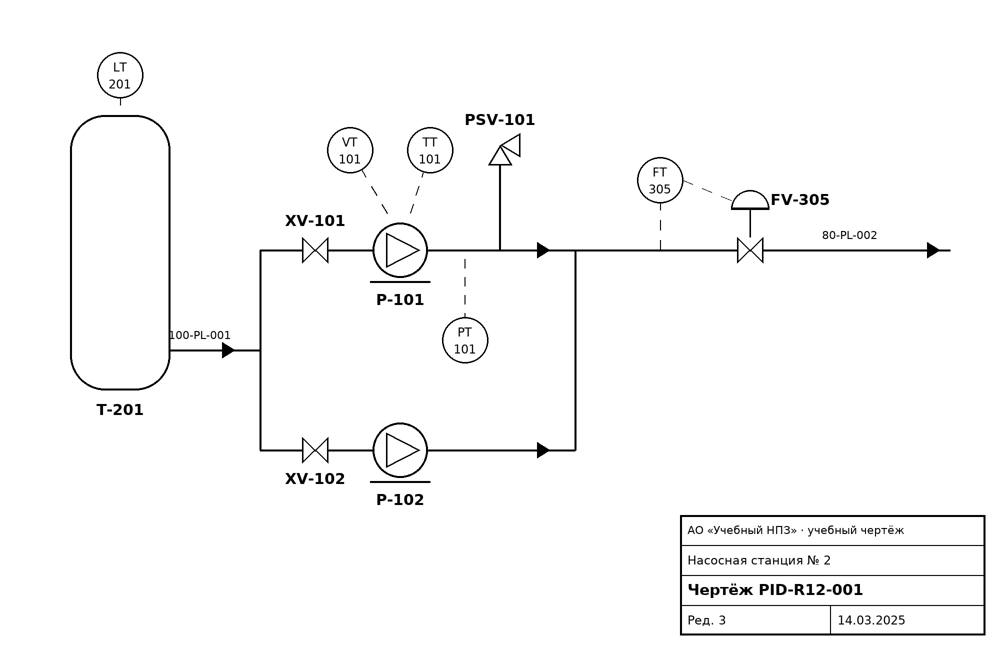

In [17]:
from PIL import Image

pid_img = Image.open(DOCS_DIR / "PID-R12-001.png")
pid_img.resize((pid_img.width // 2, pid_img.height // 2))

In [18]:
from plant_assistant.image_tasks import run_image_task

pid_truth = load_json("pid.json")
pid = run_image_task(client_for("images"), "pid", DOCS_DIR / "PID-R12-001.png", pid_truth)
s = pid["score"]
print("found:", sorted(pid["answer"]["tags"]))
print(f"precision {s['precision']:.0%}, recall {s['recall']:.0%}; invented: {s['invented']}; missed: {s['missed']}")
print("title block:", {k: pid["answer"][k] for k in ("drawing_number", "revision", "date")}, f"→ {s['title_block']}/3")

found: ['FT-305', 'FV-305', 'LT-201', 'P-101', 'P-102', 'PSV-101', 'PT-101', 'T-201', 'TT-101', 'VT-101', 'XV-101', 'XV-102']
precision 100%, recall 100%; invented: []; missed: []
title block: {'drawing_number': 'PID-R12-001', 'revision': '3', 'date': '14.03.2025'} → 3/3


Instrument bubbles show the letters and the number on two lines (`PT` over `101`): the model has to join them.
Tags are compared after normalization by code (case, spaces, Cyrillic look-alikes), as in practice 1.

**Nameplate.** The Pydantic approach from practice 1, applied to a photo with glare and perspective.

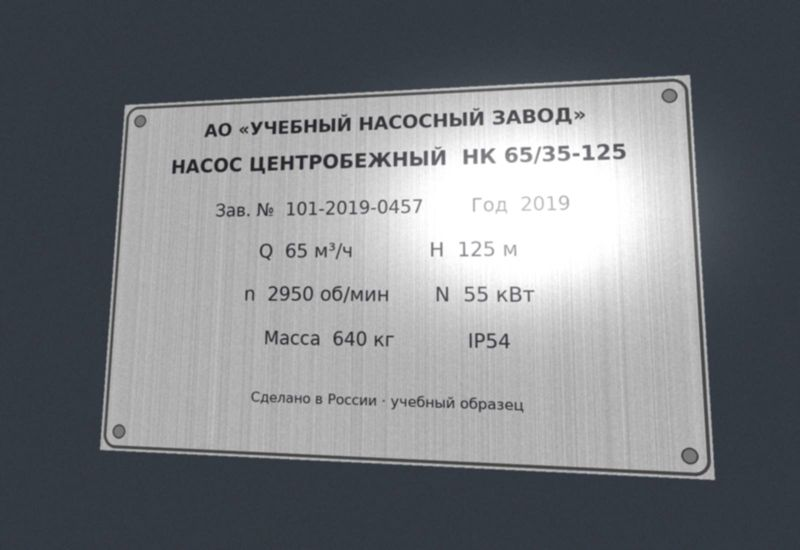

,expected,got,ok
model,НК 65/35-125,НК 65/35-125,True
serial_number,101-2019-0457,101-2019-0457,True
year,2019,2019,True
flow_m3h,65,65,True
head_m,125,125,True
speed_rpm,2950,2950,True
power_kw,55,55,True
mass_kg,640,640,True


In [19]:
plate = Image.open(DOCS_DIR / "nameplate_P-101.jpg")
show_jpeg(plate.resize((plate.width // 2, plate.height // 2)))
np_result = run_image_task(client_for("images"), "nameplate", DOCS_DIR / "nameplate_P-101.jpg", load_json("nameplate.json"))
pd.DataFrame(np_result["score"]["fields"]).T

In [20]:
# The lecturer's runs: the local 4B model, the course model and a frontier model
pd.read_csv(REFERENCE_DIR / "images.csv")

,profile,task,result,latency_s,prompt_tokens
0,local,pid,"tags 12/12 correct, recall 100%; invented: —; missed: —; title block 3/3",8.650,2713
1,local,nameplate,fields 88%; wrong: power_kw=None,4.394,1847
2,course,pid,"tags 12/12 correct, recall 100%; invented: —; missed: —; title block 3/3",2.320,2667
3,course,nameplate,fields 100%; wrong: —,1.516,1842
4,gpt-6.1-sol,pid,"tags 12/12 correct, recall 100%; invented: —; missed: —; title block 3/3",3.760,3267
5,gpt-6.1-sol,nameplate,fields 100%; wrong: —,3.397,2551


## 7. Structure, chunks, metadata, revisions

The store is the input of practice 4, so every chunk must be **citable**: document, revision, clause, page.
Steps (all rules, no model): metadata from the title page; running headers and footers removed; clause
numbers at the start of a line rebuild the tree (a number counts only if it continues the numbering, so
`720 часов` at the start of a wrapped line is not a clause); one chunk per clause; a table is one chunk
with its caption; headings become breadcrumbs and parents.

> **Poll.** How many chunks will clause 4.3 (with its sub-clauses and Table 3) produce? (a) 1 (b) 4 (c) 6

In [21]:
from plant_assistant.readers import read_pymupdf_tables
from plant_assistant.store import chunk_regulation

r12 = read_pymupdf_tables(DOCS_DIR / "R-12_rev3.pdf")  # born-digital: text layer + table finder, no OCR
meta, chunks = chunk_regulation([p["text"] for p in r12], "R-12_rev3.pdf", "pymupdf+tables", r12[0]["version"])
print(json.dumps(meta, ensure_ascii=False))
c43 = [c for c in chunks if (c.clause or "").startswith("4.3")]
pd.DataFrame([{"chunk_id": c.chunk_id, "type": c.chunk_type, "clause": c.clause, "page": c.page,
               "parent": c.parent_id, "breadcrumbs": c.breadcrumbs(), "text": c.text[:80]} for c in c43])

{"doc_id": "R-12", "title": "Вибрационный контроль насосного оборудования", "revision": 3, "effective_date": "2025-03-14", "supersedes": 2, "scope": "Насосная станция № 2"}


,chunk_id,type,clause,page,parent,breadcrumbs,text
0,R-12-r3-4.3,section,4.3,3,R-12-r3-4,R-12 ред. 3 › 4 Вибрационный контроль,4.3 Нормы вибрации
1,R-12-r3-4.3.1,clause,4.3.1,3,R-12-r3-4.3,R-12 ред. 3 › 4 Вибрационный контроль › 4.3 Нормы вибрации,4.3.1 Виброскорость измеряют на корпусах подшипников в трёх направлениях: вертик
2,R-12-r3-4.3.2,clause,4.3.2,3,R-12-r3-4.3,R-12 ред. 3 › 4 Вибрационный контроль › 4.3 Нормы вибрации,4.3.2 Результат измерения сравнивают с границами таблицы 3 для класса машины. Кл
3,R-12-r3-4.3.3,clause,4.3.3,3,R-12-r3-4.3,R-12 ред. 3 › 4 Вибрационный контроль › 4.3 Нормы вибрации,4.3.3 При превышении границы осмотра по таблице 3 оборудование осматривают в теч
4,R-12-r3-4.3.4,clause,4.3.4,3,R-12-r3-4.3,R-12 ред. 3 › 4 Вибрационный контроль › 4.3 Нормы вибрации,4.3.4 При превышении границы останова по таблице 3 оборудование немедленно остан
5,R-12-r3-table1,table,4.3,4,R-12-r3-4.3,R-12 ред. 3 › 4 Вибрационный контроль › 4.3 Нормы вибрации,"Таблица 3 — Границы виброскорости по классам машин (СКЗ, мм/с)\n|Группа оборудова"


In [22]:
table_chunk = next(c for c in c43 if c.chunk_type == "table")
print(table_chunk.text)

Таблица 3 — Границы виброскорости по классам машин (СКЗ, мм/с)
|Группа оборудования|Класс<br>машины|Граница виброскорости мм/с<br>,|Col4|
|---|---|---|---|
|**Группа оборудования**|**Класс**<br>**машины**|**осмотр**|**останов**|
|Насосы|I|2,8|4,5|
|Насосы|II|4,5|7,1|
|Компрессоры|III|7,1|11,2|
|Компрессоры|IV|11,2|18,0|
|Вентиляторы|V|5,6|9,0|


The table finder of PyMuPDF brought the rows back (compare with step 5: the plain text layer had 0 rows).
It copied the merged cell "Насосы" into both of its rows, which is good for search, and the merged header
became `Граница виброскорости мм/с ,` plus an empty `Col4`. A table is one chunk with its caption, so the
model always sees the whole table. One more domain rule: the finder also takes the two-column section 3 for
a table; we keep only tables with a caption "Таблица N —" above them (see `readers.read_pymupdf_tables`).

**The same tree from the scans.** How much of the clause structure survives each reader?

In [23]:
from plant_assistant.evaluate import structure_summary

structure_summary(["digital"] + READERS)

,clauses found,table chunks,missed (first 6)
reader,,,
Born-digital original (ceiling),55/55,0,—
"PyMuPDF, text layer",0/55,0,"1, 1.1, 1.2, 1.3, 1.4, 2"
EasyOCR,40/55,0,"3.4, 3.5, 3.6, 3.7, 4.5.2, 6.1"
Docling (+EasyOCR),13/55,3,"3.2, 3.3, 3.4, 3.5, 3.6, 3.7"
"dots.ocr 1.5, document VLM (replay)",55/55,3,—
"Qwen3.5 4B, local VLM",53/55,3,"3.2, 3.3"
"Qwen 3.8 27B, course VLM",55/55,3,—
gpt-6.1-sol (replay),55/55,3,—


**Build the store.** Both revisions of R-12 (born-digital: text layer + table finder) and both datasheets
(scans, as read by the course VLM).
The older revision stays in the store with `status = superseded` and `superseded_by = 3`: questions like
"what changed" need it, and topic 4 filters it out when it answers about the current rules.

In [24]:
from plant_assistant import STORE_DIR
from plant_assistant.store import build_store

summary = build_store(scan_reader="vlm:course", folder=STORE_DIR)
print(summary)
docs = pd.read_json(STORE_DIR / "documents.jsonl", lines=True)
docs[["revision", "superseded_by"]] = docs[["revision", "superseded_by"]].astype("Int64")
docs[["doc_id", "revision", "effective_date", "status", "superseded_by", "source_file", "parser", "content_hash"]]

{'folder': 'store', 'documents': 4, 'chunks': 120, 'by_type': {'section': 28, 'clause': 84, 'table': 6, 'datasheet': 2}, 'clause_4_3_rev3': ['R-12-r3-4.3', 'R-12-r3-4.3.1', 'R-12-r3-4.3.2', 'R-12-r3-4.3.3', 'R-12-r3-4.3.4', 'R-12-r3-table1']}


,doc_id,revision,effective_date,status,superseded_by,source_file,parser,content_hash
0,R-12,2,2022-06-01,superseded,3,R-12_rev2.pdf,pymupdf+tables,e477df1ea35e8c76
1,R-12,3,2025-03-14,in force,<NA>,R-12_rev3.pdf,pymupdf+tables,19f451783e25dbf5
2,PS-101,<NA>,None,in force,<NA>,PS-101_scan.pdf,vlm:course,7208c4391736ceeb
3,DS-P-205,<NA>,None,in force,<NA>,DS-P-205_scan.pdf,vlm:course,e654cce1d6dc1c4c


In [25]:
store = pd.read_json(STORE_DIR / "chunks.jsonl", lines=True)
both = store[(store["chunk_type"] == "table") & store["text"].str.contains("Таблица 3")]
for _, ch in both.iterrows():
    row2 = [line for line in ch["text"].splitlines() if "|II|" in line.replace(" ", "")]
    print(f"revision {int(ch['revision'])} ({ch['status']}): {row2}")

revision 2 (superseded): ['|Насосы|II|5,0|7,1|']
revision 3 (in force): ['|Насосы|II|4,5|7,1|']


## 8. Mini-eval end-to-end

50 questions about the scanned documents, built by the rules of lecture 2: each comes from a known clause,
table row or datasheet line; the answer is a number with a unit; 8 questions are negative ("not stated").
For each question the reader's text of the page with the answer goes to the model (search is topic 4),
the model answers in JSON, and **code** checks the number and the unit. The same model answers for every
reader, so a difference between readers is a difference in what they read.

`digital` is the ceiling: the text layer of the born-digital original.

In [26]:
from plant_assistant.docs import load_questions

questions = load_questions()
print(pd.Series([q["slice"] for q in questions]).value_counts().to_dict())
pd.DataFrame(questions)[["id", "question", "value", "unit", "where", "slice"]].head(8)

{'text': 17, 'table': 14, 'not_stated': 8, 'datasheet': 6, 'rare_language': 5}


,id,question,value,unit,where,slice
0,t01,What is the inspection limit of vibration velocity for class I machines in R-12?,"2,8",mm/s,Table 3,table
1,t02,What is the stop limit of vibration velocity for class I machines in R-12?,"4,5",mm/s,Table 3,table
2,t03,What is the inspection limit of vibration velocity for class II machines in R-12?,"4,5",mm/s,Table 3,table
3,t04,What is the stop limit of vibration velocity for class II machines in R-12?,"7,1",mm/s,Table 3,table
4,t05,What is the inspection limit of vibration velocity for class III machines in R-12?,"7,1",mm/s,Table 3,table
5,t06,What is the stop limit of vibration velocity for class III machines in R-12?,"11,2",mm/s,Table 3,table
6,t07,What is the inspection limit of vibration velocity for class IV machines in R-12?,"11,2",mm/s,Table 3,table
7,t08,What is the stop limit of vibration velocity for class IV machines in R-12?,"18,0",mm/s,Table 3,table


> **Predict, then run.** Docling against EasyOCR on these scans: better, worse or not different?

Answers come from the lecturer's run of the course model (replay, seconds). With the course token you can
run it live: set `QA_LIVE = True` (about 350 calls, 2–3 minutes).

In [27]:
from plant_assistant.evaluate import qa_pairs, qa_summary, reader_pages
from plant_assistant.qa import run_qa

QA_LIVE = False
qa_client = client_for("qa") if QA_LIVE else ReplayClient(REPLAY_DIR / "qa_course.jsonl")
results = []
for reader in ["digital"] + READERS:
    results += run_qa(reader, reader_pages(reader), questions, qa_client, concurrency=8 if QA_LIVE else 1)
qa_summary(results)

,accuracy,95% CI,table,text,datasheet,rare_language,not_stated,lost in reading,lost in the model
reader,,,,,,,,,
Born-digital original (ceiling),0.980,90%–100%,14/14,17/17,6/6,5/5,7/8,0,1
"PyMuPDF, text layer",0.160,8%–29%,0/14,0/17,0/6,0/5,8/8,42,0
EasyOCR,0.840,71%–92%,11/14,14/17,5/6,4/5,8/8,8,0
Docling (+EasyOCR),0.560,42%–69%,4/14,11/17,4/6,1/5,8/8,22,0
"dots.ocr 1.5, document VLM (replay)",0.980,90%–100%,14/14,17/17,6/6,5/5,7/8,0,1
"Qwen3.5 4B, local VLM",0.980,90%–100%,14/14,17/17,6/6,5/5,7/8,0,1
"Qwen 3.8 27B, course VLM",0.980,90%–100%,14/14,17/17,6/6,5/5,7/8,0,1
gpt-6.1-sol (replay),0.980,90%–100%,14/14,17/17,6/6,5/5,7/8,0,1


In [28]:
PAIRS = [("vlm:course", "docling"), ("docling", "easyocr"), ("vlm:course", "easyocr"), ("easyocr", "pymupdf"),
         ("vlm:dots-ocr", "docling"), ("vlm:dots-ocr", "vlm:course"), ("vlm:course", "vlm:local"),
         ("vlm:gpt-6.1-sol", "vlm:course"), ("digital", "vlm:course")]
qa_pairs(results, PAIRS)

,A,B,A − B,95% CI,only A right,only B right,verdict
0,"Qwen 3.8 27B, course VLM",Docling (+EasyOCR),+42%,+28% … +56%,22,1,A is better
1,Docling (+EasyOCR),EasyOCR,-28%,-42% … -14%,1,15,A is worse
2,"Qwen 3.8 27B, course VLM",EasyOCR,+14%,+4% … +26%,8,1,A is better
3,EasyOCR,"PyMuPDF, text layer",+68%,+54% … +80%,34,0,A is better
4,"dots.ocr 1.5, document VLM (replay)",Docling (+EasyOCR),+42%,+28% … +56%,22,1,A is better
5,"dots.ocr 1.5, document VLM (replay)","Qwen 3.8 27B, course VLM",+0%,+0% … +0%,0,0,not different
6,"Qwen 3.8 27B, course VLM","Qwen3.5 4B, local VLM",+0%,+0% … +0%,0,0,not different
7,gpt-6.1-sol (replay),"Qwen 3.8 27B, course VLM",+0%,+0% … +0%,0,0,not different
8,Born-digital original (ceiling),"Qwen 3.8 27B, course VLM",+0%,+0% … +0%,0,0,not different


- An interval of ±10–14 points on 50 questions is normal: two strong readers will often be **not different**.
- `not_stated` questions are answered "correctly" even by the empty text layer: a negative question checks that
  the model does not invent, not that the reader reads. Look at the slices, not only at the total.
- Slices of 5–14 questions are shown as counts, not percentages.

**Where was the answer lost?** We already have the answer with the ground truth text: the `digital` row.
If the model answered a question right on the born-digital text and wrong on a reader's text, the reader lost
it (`reading`). If it was wrong on the born-digital text too, the model is the failing link (`model`).
`number_on_page` shows whether the right number was still on the reader's page: often it is, but in the wrong
row of a broken table.

In [29]:
from plant_assistant.qa import attribute

res = pd.DataFrame(attribute([dict(r) for r in results]))
wrong = res[~res["correct"] & res["reader"].isin(["easyocr", "docling", "vlm:course"])]
wrong[["reader", "id", "slice", "question", "expected", "value", "unit", "reason", "number_on_page", "lost_at"]]

,reader,id,slice,question,expected,value,unit,reason,number_on_page,lost_at
101,easyocr,t02,table,What is the stop limit of vibration velocity for class I machines in R-12?,"4,5","2,8",мм/с,wrong value,True,reading
106,easyocr,t07,table,What is the inspection limit of vibration velocity for class IV machines in R-12?,"11,2","18,0",мм/с,wrong value,True,reading
108,easyocr,t09,table,What is the inspection limit of vibration velocity for fans (class V) in R-12?,"5,6","9,0",мм/с,wrong value,True,reading
114,easyocr,c01,text,What is the upper end of the measuring range of vibration velocity for the instruments?,100,100,None,wrong unit,True,reading
122,easyocr,c09,text,What is the highest permitted temperature of the bearing outer ring?,80,80,*С,wrong unit,True,reading
126,easyocr,c13,text,What is the largest permitted radial misalignment of the shafts after a repair?,"0,05",None,None,said not stated,False,reading
131,easyocr,d01,datasheet,What is the rated flow of pump P-101?,65,65,мэ/ч,wrong unit,True,reading
138,easyocr,z02,rare_language,What is the rated head of pump P-205?,80,None,None,said not stated,True,reading
150,docling,t01,table,What is the inspection limit of vibration velocity for class I machines in R-12?,"2,8",None,None,said not stated,False,reading
151,docling,t02,table,What is the stop limit of vibration velocity for class I machines in R-12?,"4,5",None,None,said not stated,True,reading


## 9. Results and next steps

**Check yourself:** `store/` is built; your tables in steps 4 and 8 match `reference/results.md` (live runs may
differ by a question or two: that is why we use intervals).

**What you built:** triage, six readers with one interface, reading metrics beyond CER (numbers, length,
repetitions), table scores and representations, a VLM on a drawing and a photo, structural chunks with
metadata and revisions, and an end-to-end mini-eval with paired comparison and the step where an answer was lost.

**Typical mistakes** (check before you trust a number):
- a scan was sent to the text layer: empty pages, no error;
- Tesseract without the `rus` language data, or a parser whose OCR language was not set;
- a VLM answer wrapped in a ```` ```markdown ```` block (strip it, as `readers.strip_fence` does);
- a VLM "fixed" `4,8` to `4.8` or `мм/с` to `mm/s`: compare numbers by value, but count such rewrites;
- low CER taken as "no invented text": look at the length ratio and the numbers;
- a table cut into pieces by chunking, or a clause number broken by OCR (`4.З.2`) that breaks the tree;
- "reader X is better" from one run or from two averages without a paired comparison.

**Homework (optional, see the README for the full list):**
1. Preprocessing: deskew and binarize the scans before EasyOCR or Tesseract; measure CER per page before and after.
2. "CER on what matters": CER only on numbers, units and tags. Does the ranking of readers change?
3. Routing: the cheapest reader for every page, the VLM only where a check fails (empty text, few numbers,
   a table not recovered). Accuracy and cost against "VLM on every page".
4. Your own document: an open technical document, 5 questions with answers, the mandatory readers, accuracy.

**Next practice (topic 4):** `store/` becomes a search index; the questions of step 8 become a retrieval eval.